# PORTUGUESE BANK MARKETING PROJECT

**Business Understanding**

- **Domain:** Banking / Finance
- **Business Problem:** The bank wants to identify customers who are likely to subscribe to a term deposit.
- **Objective:** Analyse customer and campaign data and build a model to predict term-deposit subscription.


---

# Project Workflow

1. **Task 1 – Data Analysis Report:** understand the dataset, clean and explore the data, visualize patterns, and summarize business insights.
2. **Task 2 – Predictive Model:** prepare modelling features, split the data, train classification model(s), and evaluate predictions for `y`.
3. **Task 3 – Business Recommendations:** convert the analysis and model results into actionable suggestions for the bank marketing team.

---



# Portuguese Bank Marketing – Task 1: Complete Data Analysis Report

**Domain:** Finance / Banking  
**Objective:** Explore the Portuguese bank telemarketing dataset and identify patterns associated with customers subscribing to a term deposit.

### Important project note
- The target column is `y` (`yes` / `no`).
- The dataset contains call campaign information from May 2008 to November 2010.
- `duration` is known only after a call. It is useful for descriptive analysis, but **must not be used as a predictor in a pre-call production model** (that is Task 2).
- The file is semicolon-separated (`;`), not comma-separated.

Run the notebook from top to bottom. The charts and tables are generated from the actual data.

## 1. Import libraries

In [1]:
import os
import glob
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.figsize"] = (10, 5)


## 2. Load the correct CSV file
The notebook first looks for `bank-additional-full.csv` in the current folder. If it is not present, it searches ZIP files in the current folder for `Data/bank-additional/bank-additional-full.csv`.

In [2]:
import os
import pandas as pd

print("Current Folder:", os.getcwd())
print("Available Files:", os.listdir())

df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

df.head()



Current Folder: C:\Users\Home\project 1
Available Files: ['.ipynb_checkpoints', 'bank-additional-full.csv', 'Portuguese_Bank_Marketing_Project.ipynb']
Dataset Loaded Successfully!
Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Dataset overview

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nFirst five records:")
display(df.head())

print("\\nRandom five records:")
display(df.sample(5, random_state=42))


Rows and columns: (41188, 21)
\nColumn names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


\nRandom five records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
32884,57,technician,married,high.school,no,no,yes,cellular,may,mon,371,1,999,1,failure,-1.8,92.893,-46.2,1.299,5099.1,no
3169,55,unknown,married,unknown,unknown,yes,no,telephone,may,thu,285,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no
32206,33,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,52,1,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1,no
9403,36,admin.,married,high.school,no,no,no,telephone,jun,fri,355,4,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,no
14020,27,housemaid,married,high.school,no,yes,no,cellular,jul,fri,189,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no


## 4. Data dictionary
The source brief describes 20 input variables and one output variable (`y`). The table below summarizes their meaning.

In [4]:
data_dictionary = pd.DataFrame({
    "Column": [
        "age", "job", "marital", "education", "default", "housing", "loan",
        "contact", "month", "day_of_week", "duration", "campaign", "pdays",
        "previous", "poutcome", "emp.var.rate", "cons.price.idx",
        "cons.conf.idx", "euribor3m", "nr.employed", "y"
    ],
    "Meaning": [
        "Customer age", "Type of job", "Marital status", "Education level",
        "Has credit in default?", "Has a housing loan?", "Has a personal loan?",
        "Contact communication type", "Last contact month", "Last contact weekday",
        "Last contact duration in seconds", "Contacts in current campaign",
        "Days since previous campaign contact (999 = not previously contacted)",
        "Contacts before current campaign", "Outcome of previous campaign",
        "Employment variation rate", "Consumer price index",
        "Consumer confidence index", "3-month Euribor rate",
        "Number of employees", "Subscribed to a term deposit? (target)"
    ]
})
display(data_dictionary)


,Column,Meaning
0,age,Customer age
1,job,Type of job
2,marital,Marital status
3,education,Education level
4,default,Has credit in default?
5,housing,Has a housing loan?
6,loan,Has a personal loan?
7,contact,Contact communication type
8,month,Last contact month
9,day_of_week,Last contact weekday


## 5. Data quality checks

In [5]:
# Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)
display(missing)

# Duplicate records
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

# Categorical columns and special 'unknown' values
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
unknown_summary = pd.DataFrame({
    "Unknown_Count": {c: (df[c].astype(str).str.lower() == "unknown").sum() for c in cat_cols}
})
unknown_summary["Unknown_Percent"] = (unknown_summary["Unknown_Count"] / len(df) * 100).round(2)
display(unknown_summary.sort_values("Unknown_Count", ascending=False))

# Remove exact duplicate rows for analysis; retain original df unchanged
df_analysis = df.drop_duplicates().copy()
print("Shape after removing exact duplicates:", df_analysis.shape)


,Missing_Count,Missing_Percent
age,0,0.0
campaign,0,0.0
nr.employed,0,0.0
euribor3m,0,0.0
cons.conf.idx,0,0.0
cons.price.idx,0,0.0
emp.var.rate,0,0.0
poutcome,0,0.0
previous,0,0.0
pdays,0,0.0


Exact duplicate rows: 12


,Unknown_Count,Unknown_Percent
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


Shape after removing exact duplicates: (41176, 21)


### Data quality interpretation
- A value of `unknown` is a recorded category, not a pandas missing value (`NaN`). Review it before deciding whether to keep, impute, or group it.
- `pdays = 999` is a special code meaning the customer was not previously contacted. Do not interpret 999 as an ordinary number of days.
- Exact duplicate rows are removed in `df_analysis` for the analysis below; the original `df` remains unchanged.

## 6. Descriptive statistics

In [6]:
num_cols = df_analysis.select_dtypes(include=np.number).columns.tolist()
display(df_analysis[num_cols].describe().T)

print("Categorical summary:")
display(df_analysis[cat_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


Categorical summary:


,count,unique,top,freq
job,41176,12,admin.,10419
marital,41176,4,married,24921
education,41176,8,university.degree,12164
default,41176,3,no,32577
housing,41176,3,yes,21571
loan,41176,3,no,33938
contact,41176,2,cellular,26135
month,41176,10,may,13767
day_of_week,41176,5,thu,8618
poutcome,41176,3,nonexistent,35551


## 7. Target variable analysis

,Customers,Percentage
y,,
no,36537,88.73
yes,4639,11.27


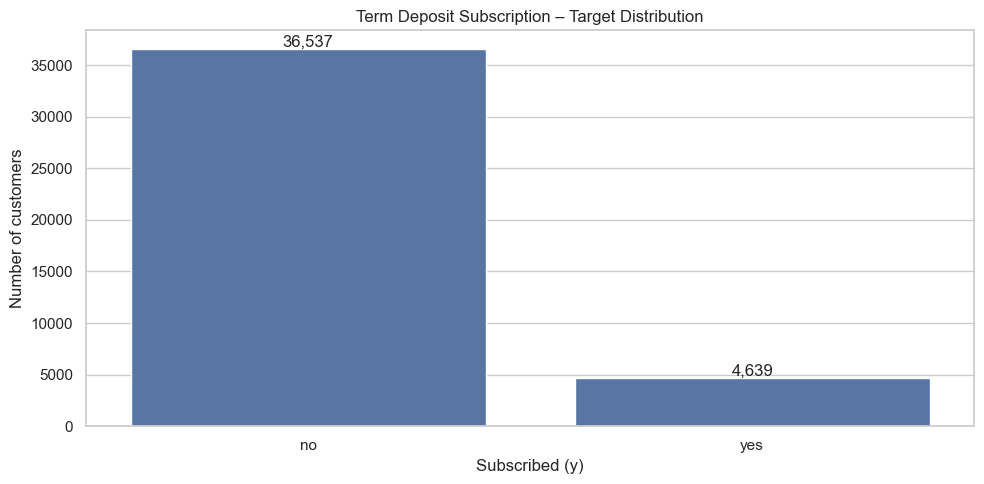

Subscription rate: 11.27%
Non-subscription rate: 88.73%


In [7]:
target_counts = df_analysis["y"].value_counts().reindex(["no", "yes"]).fillna(0)
target_pct = (target_counts / target_counts.sum() * 100).round(2)
target_summary = pd.DataFrame({"Customers": target_counts.astype(int), "Percentage": target_pct})
display(target_summary)

ax = sns.countplot(data=df_analysis, x="y", order=["no", "yes"])
ax.set_title("Term Deposit Subscription – Target Distribution")
ax.set_xlabel("Subscribed (y)")
ax.set_ylabel("Number of customers")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

yes_rate = (df_analysis["y"].eq("yes").mean() * 100)
print(f"Subscription rate: {yes_rate:.2f}%")
print(f"Non-subscription rate: {100-yes_rate:.2f}%")


## 8. Univariate analysis – numerical variables

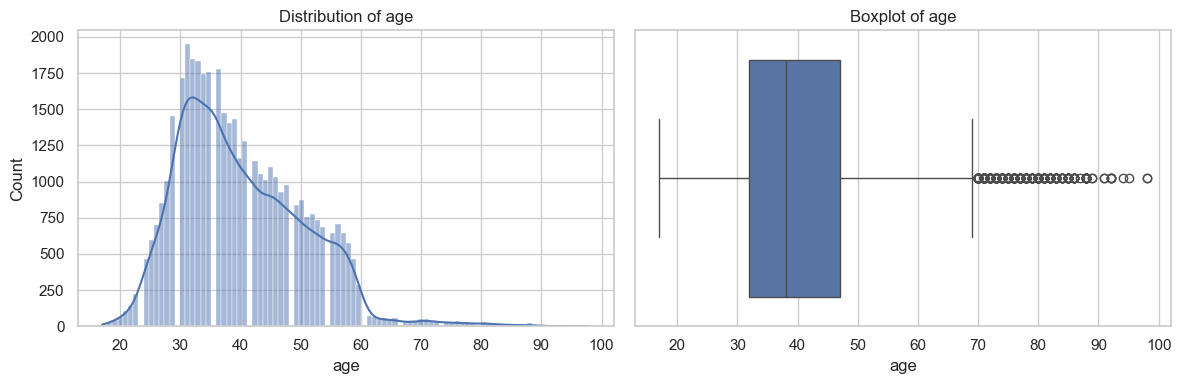

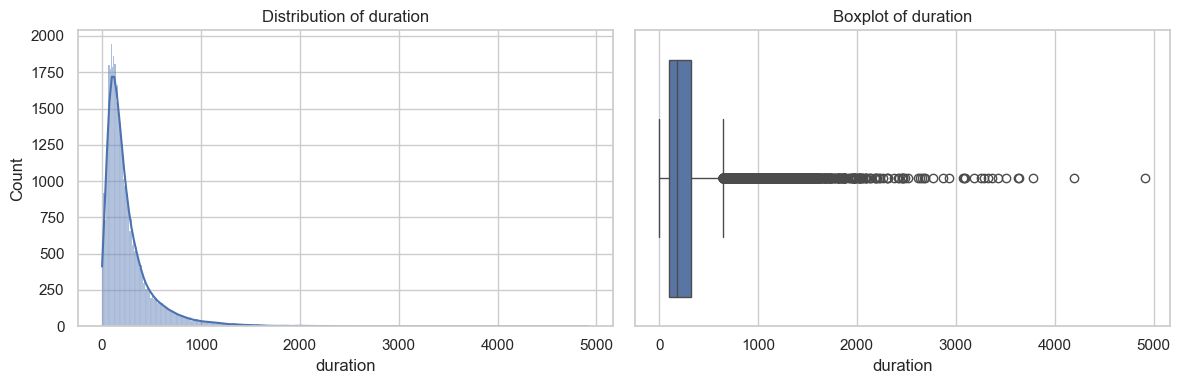

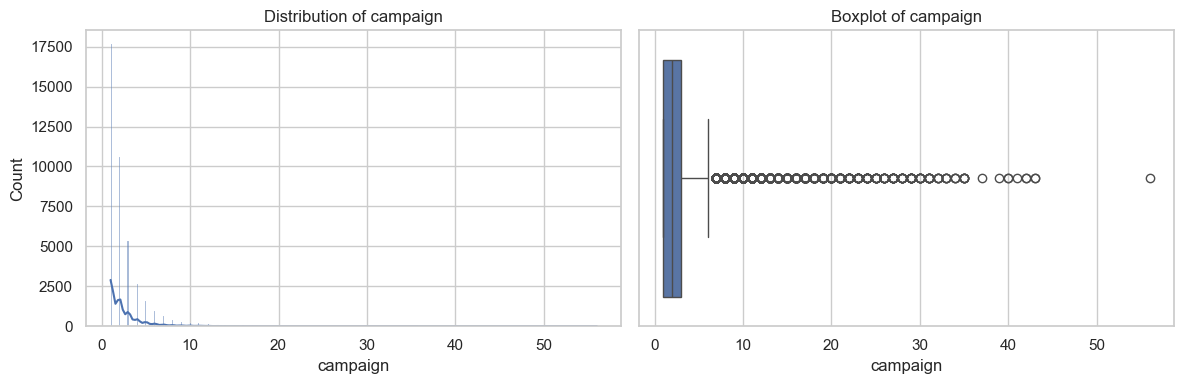

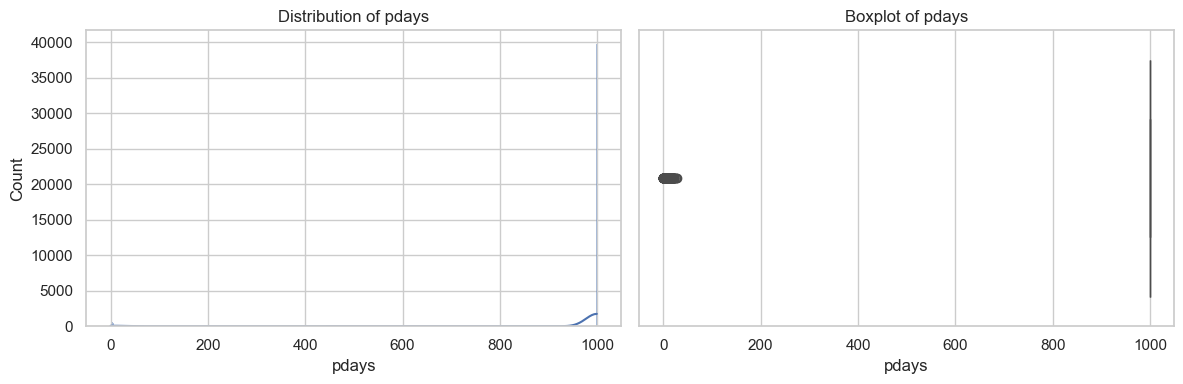

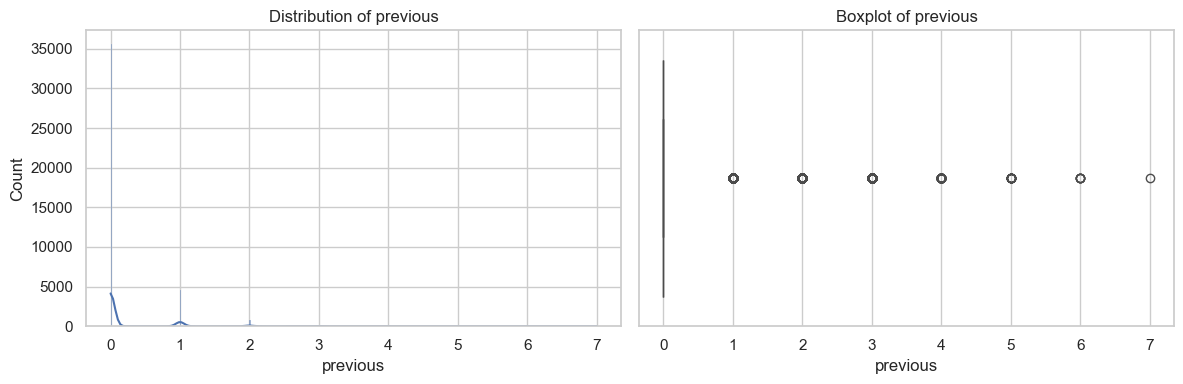

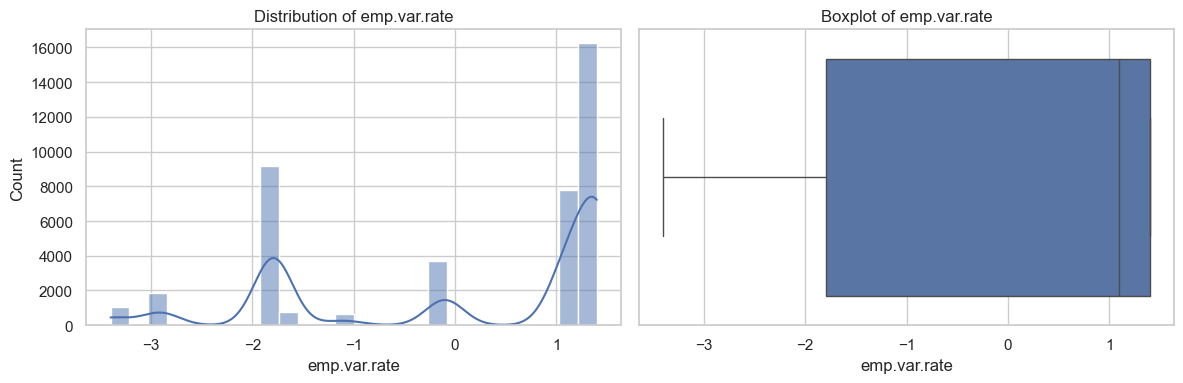

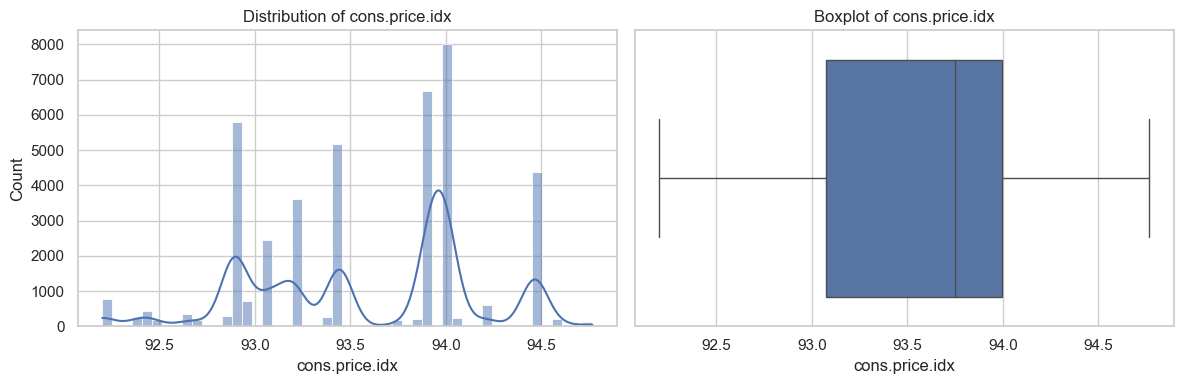

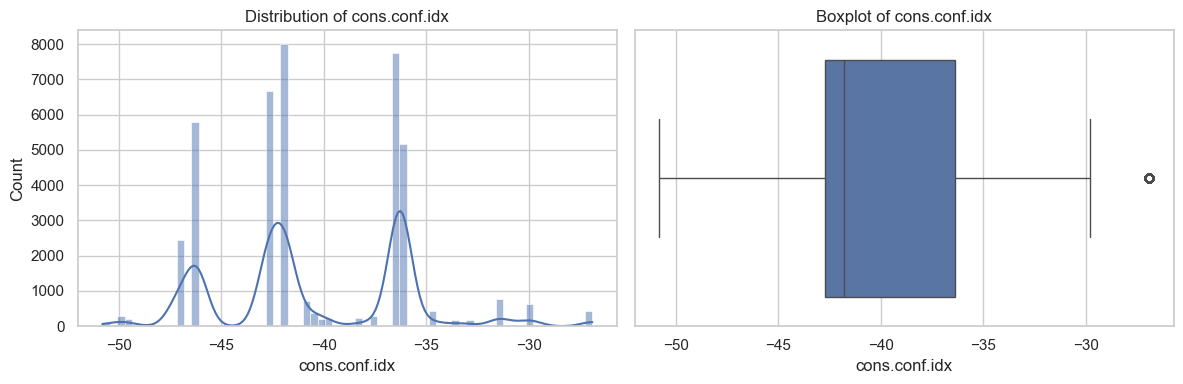

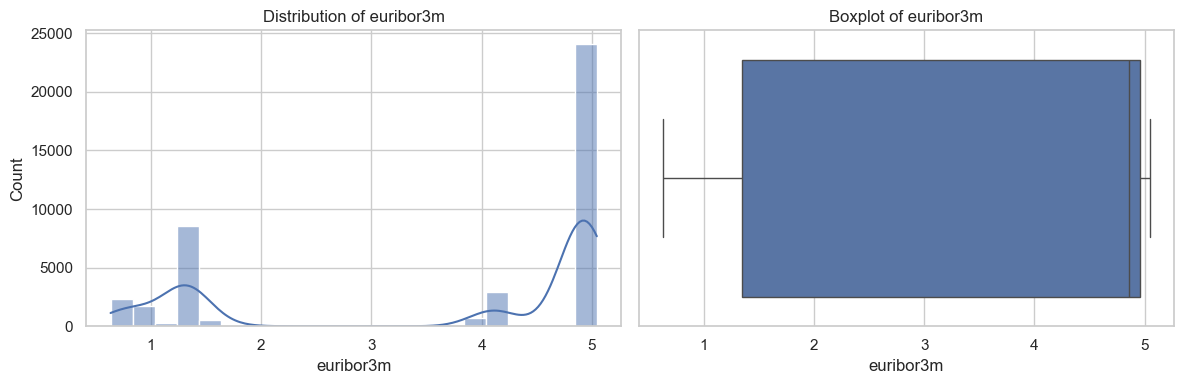

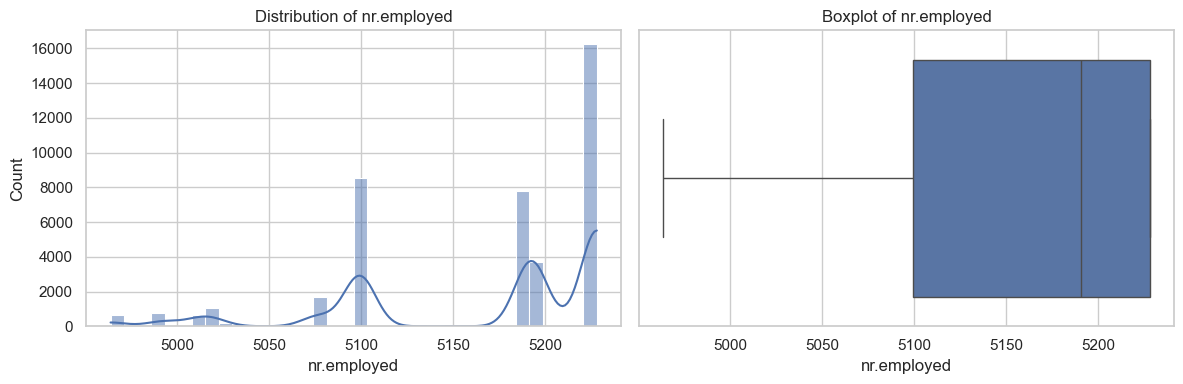

In [8]:
numeric_for_plot = ["age", "duration", "campaign", "pdays", "previous",
                    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
                    "euribor3m", "nr.employed"]
numeric_for_plot = [c for c in numeric_for_plot if c in df_analysis.columns]

for col in numeric_for_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(data=df_analysis, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    sns.boxplot(data=df_analysis, x=col, ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()


## 9. Univariate analysis – categorical variables

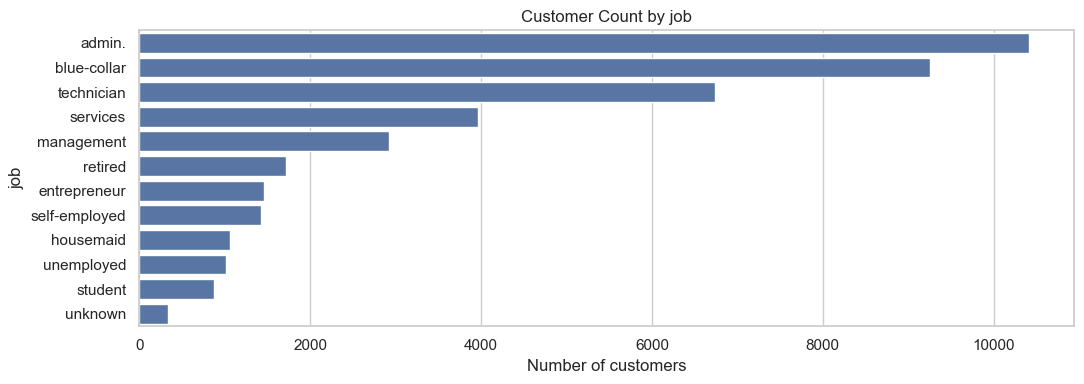

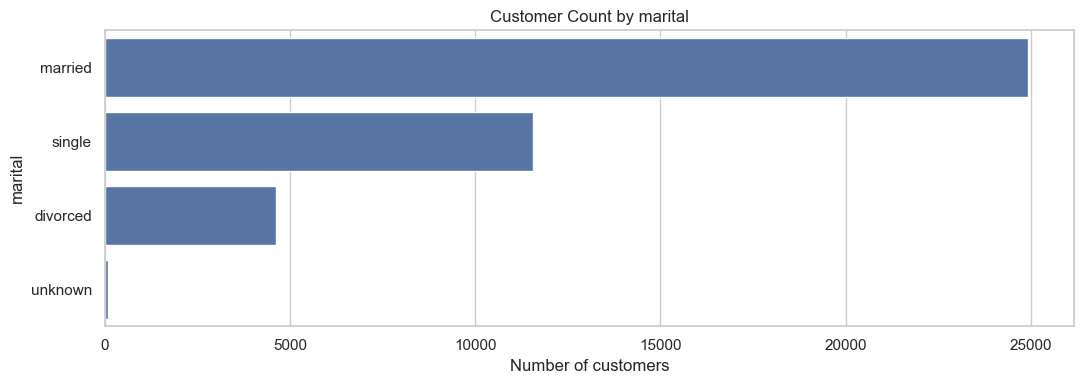

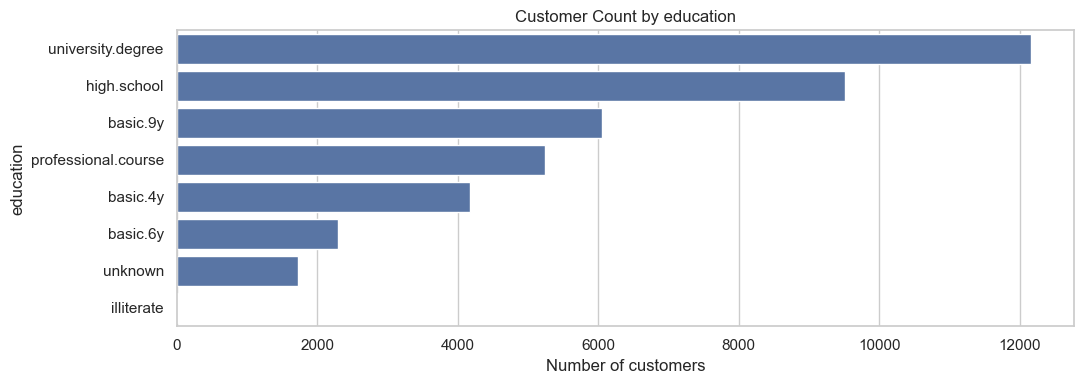

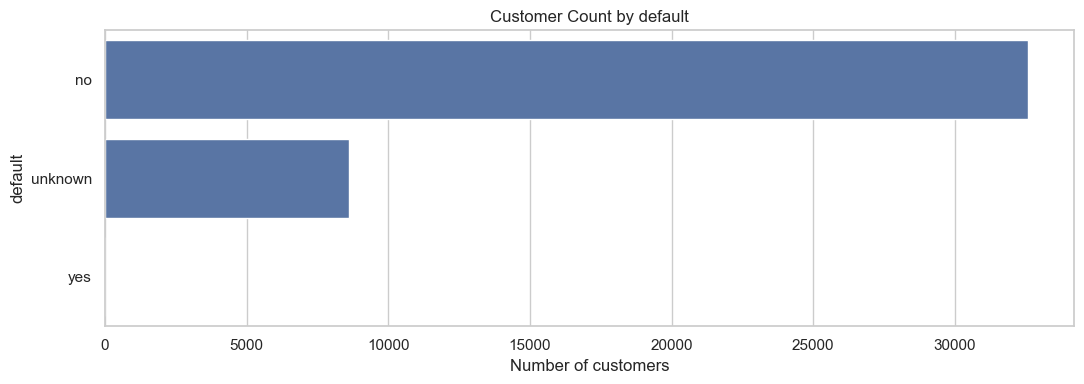

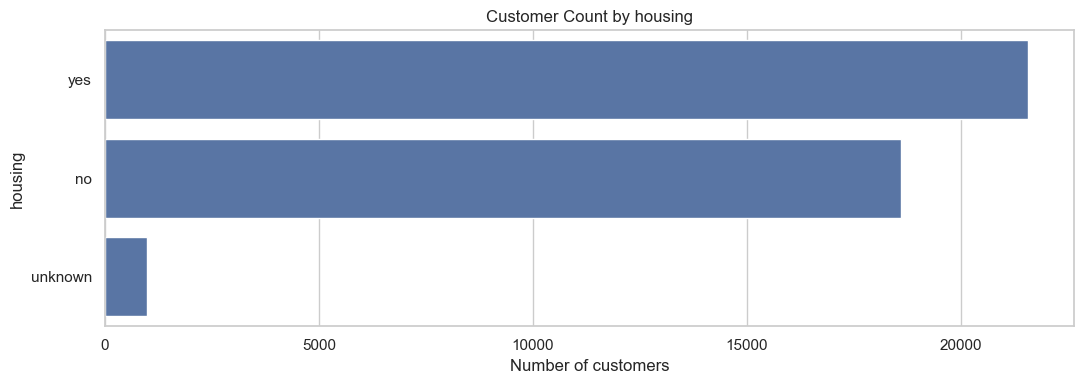

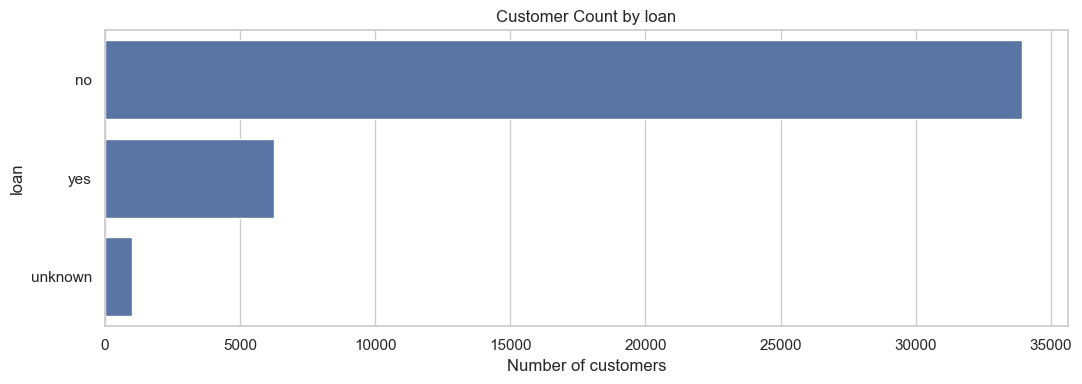

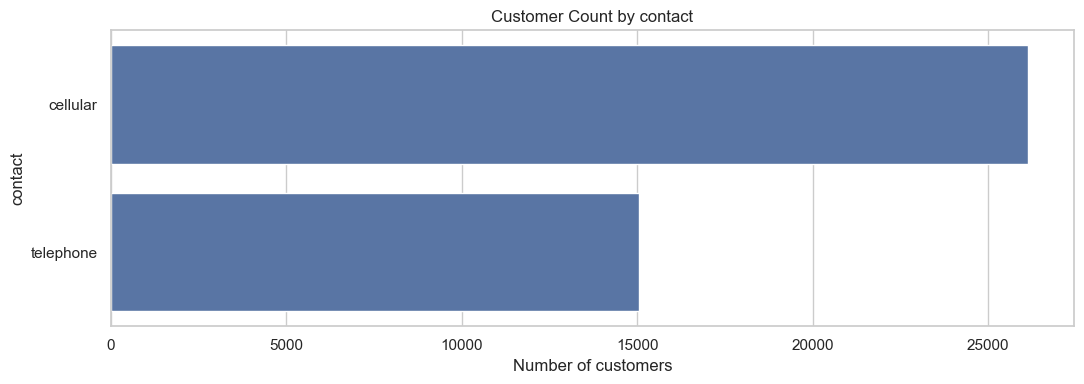

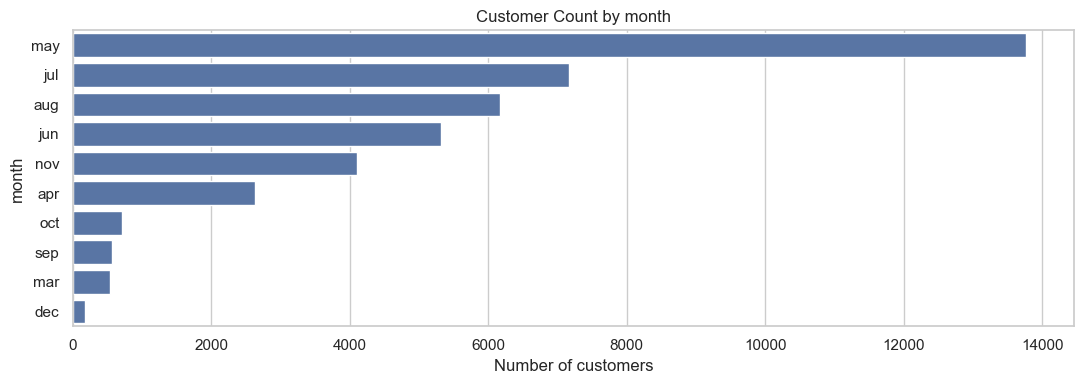

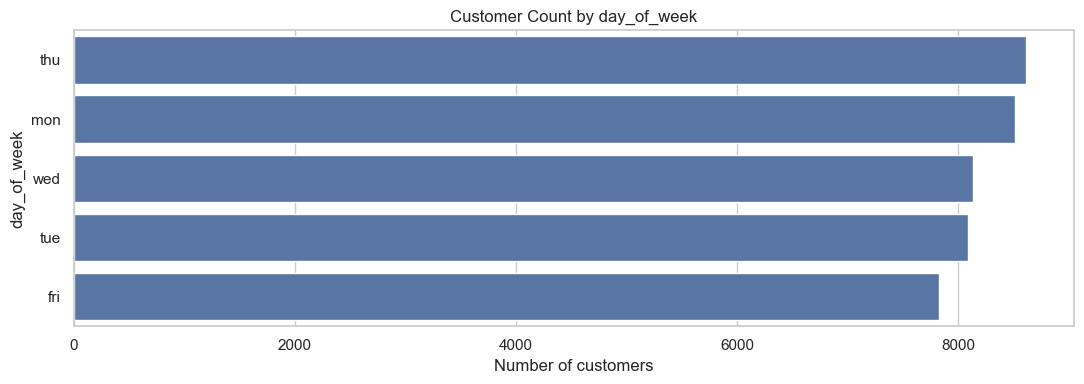

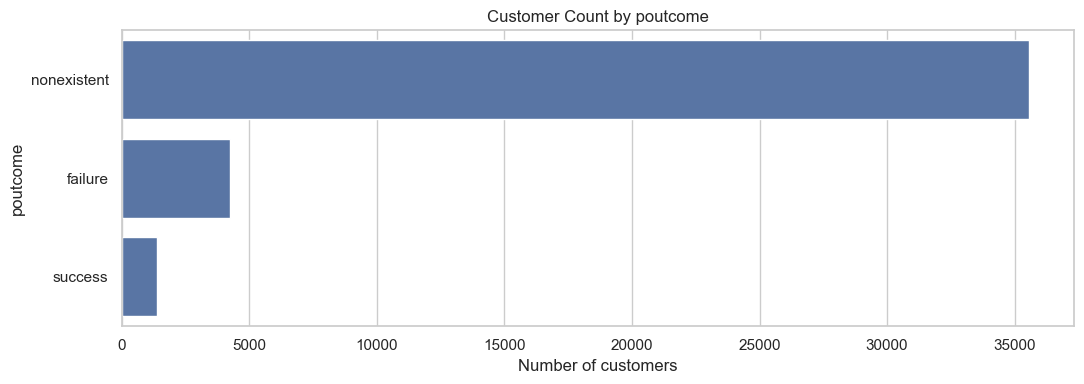

In [9]:
categorical_for_plot = ["job", "marital", "education", "default", "housing",
                        "loan", "contact", "month", "day_of_week", "poutcome"]
categorical_for_plot = [c for c in categorical_for_plot if c in df_analysis.columns]

for col in categorical_for_plot:
    order = df_analysis[col].value_counts().index
    plt.figure(figsize=(11, 4))
    sns.countplot(data=df_analysis, y=col, order=order)
    plt.title(f"Customer Count by {col}")
    plt.xlabel("Number of customers")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


## 10. Bivariate analysis – subscription rate by customer profile
Subscription rate is calculated as the percentage of customers with `y = yes` in each group. Counts are shown alongside rates to avoid over-interpreting very small groups.

\nSubscription by job


,job,customers,subscriptions,subscription_rate_pct
8,student,875,275,31.428571
5,retired,1718,434,25.261932
10,unemployed,1014,144,14.201183
0,admin.,10419,1351,12.966695
4,management,2924,328,11.217510
11,unknown,330,37,11.212121
9,technician,6739,730,10.832468
6,self-employed,1421,149,10.485574
3,housemaid,1060,106,10.000000
2,entrepreneur,1456,124,8.516484


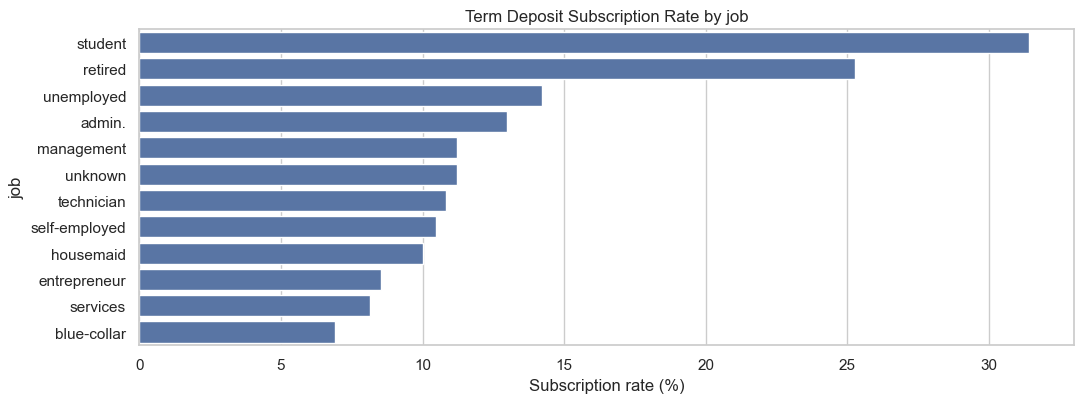

\nSubscription by marital


,marital,customers,subscriptions,subscription_rate_pct
3,unknown,80,12,15.000000
2,single,11564,1620,14.008993
0,divorced,4611,476,10.323140
1,married,24921,2531,10.156093


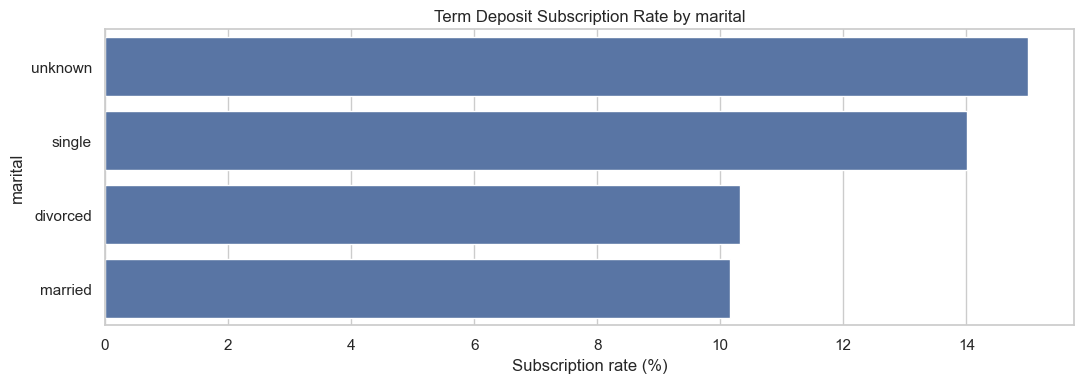

\nSubscription by education


,education,customers,subscriptions,subscription_rate_pct
7,unknown,1730,251,14.508671
6,university.degree,12164,1669,13.720816
5,professional.course,5240,595,11.354962
3,high.school,9512,1031,10.838940
0,basic.4y,4176,428,10.249042
1,basic.6y,2291,188,8.206024
2,basic.9y,6045,473,7.824648


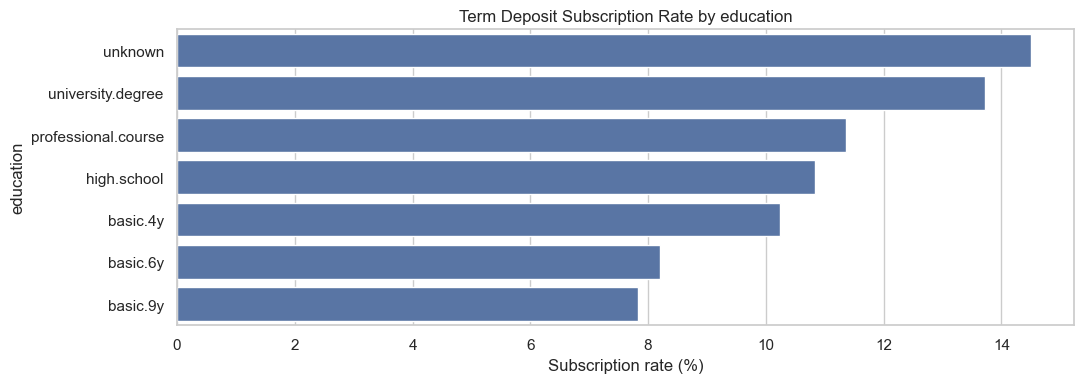

\nSubscription by default


,default,customers,subscriptions,subscription_rate_pct
0,no,32577,4196,12.880253
1,unknown,8596,443,5.153560


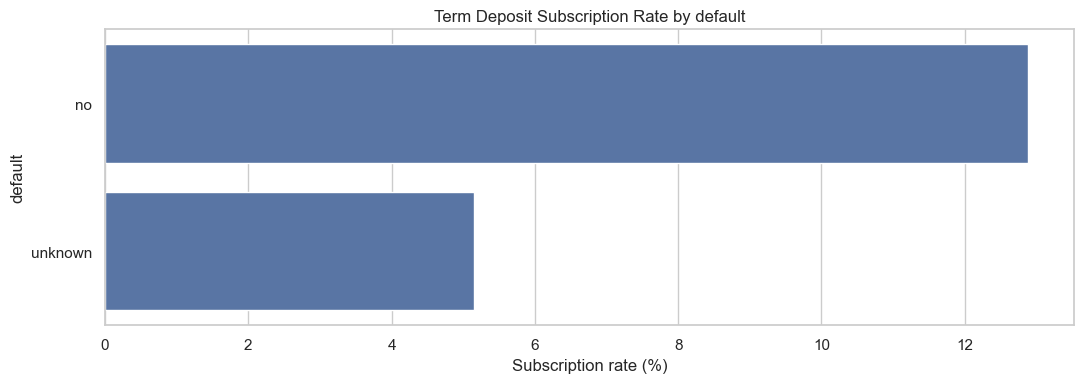

\nSubscription by housing


,housing,customers,subscriptions,subscription_rate_pct
2,yes,21571,2507,11.622085
0,no,18615,2025,10.878324
1,unknown,990,107,10.808081


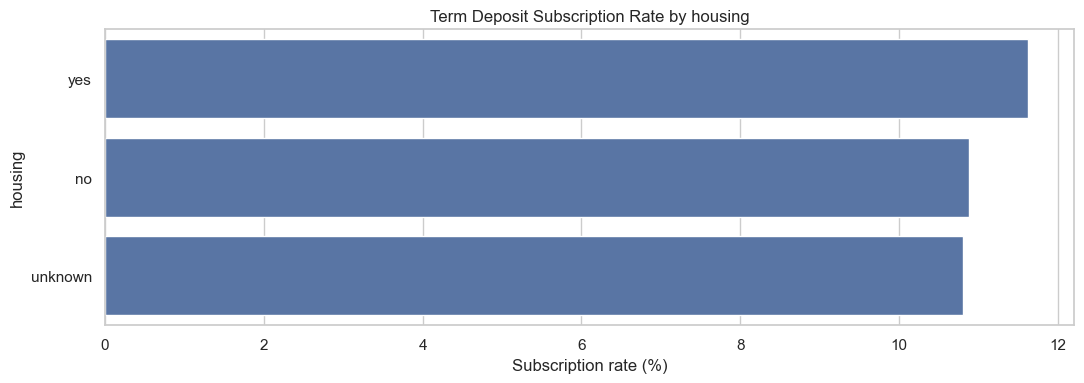

\nSubscription by loan


,loan,customers,subscriptions,subscription_rate_pct
0,no,33938,3849,11.341269
2,yes,6248,683,10.931498
1,unknown,990,107,10.808081


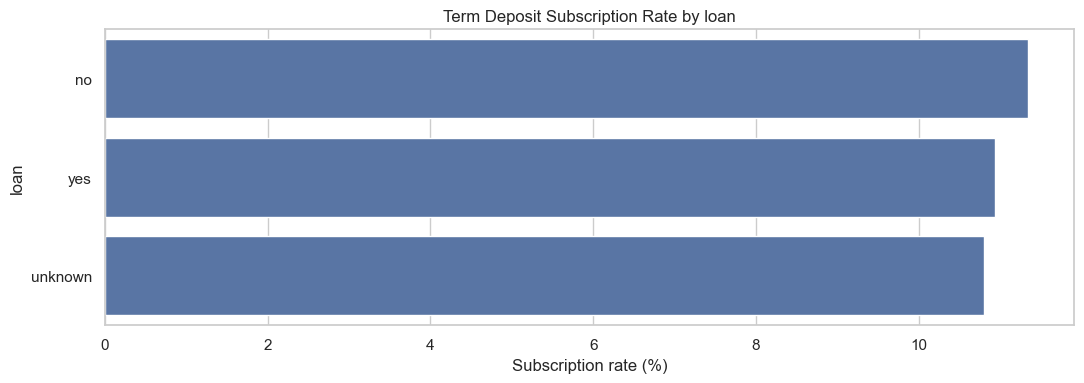

\nSubscription by contact


,contact,customers,subscriptions,subscription_rate_pct
0,cellular,26135,3852,14.738856
1,telephone,15041,787,5.232365


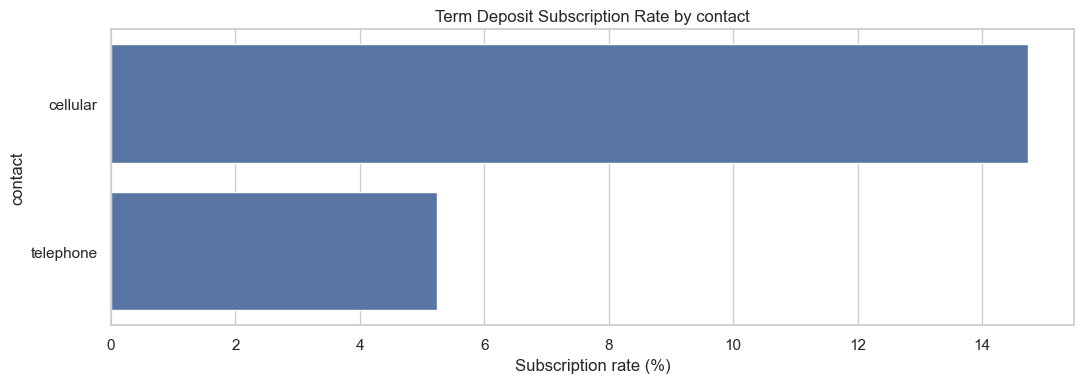

\nSubscription by month


,month,customers,subscriptions,subscription_rate_pct
5,mar,546,276,50.549451
2,dec,182,89,48.901099
9,sep,570,256,44.912281
8,oct,717,315,43.933054
0,apr,2631,539,20.486507
1,aug,6176,655,10.605570
4,jun,5318,559,10.511470
7,nov,4100,416,10.146341
3,jul,7169,648,9.038918
6,may,13767,886,6.435680


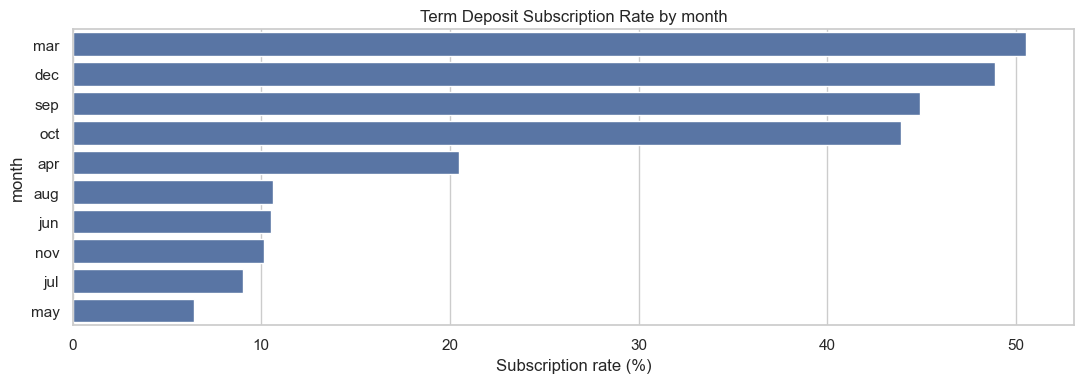

\nSubscription by day_of_week


,day_of_week,customers,subscriptions,subscription_rate_pct
2,thu,8618,1044,12.114180
3,tue,8086,953,11.785803
4,wed,8134,949,11.667076
0,fri,7826,846,10.810120
1,mon,8512,847,9.950658


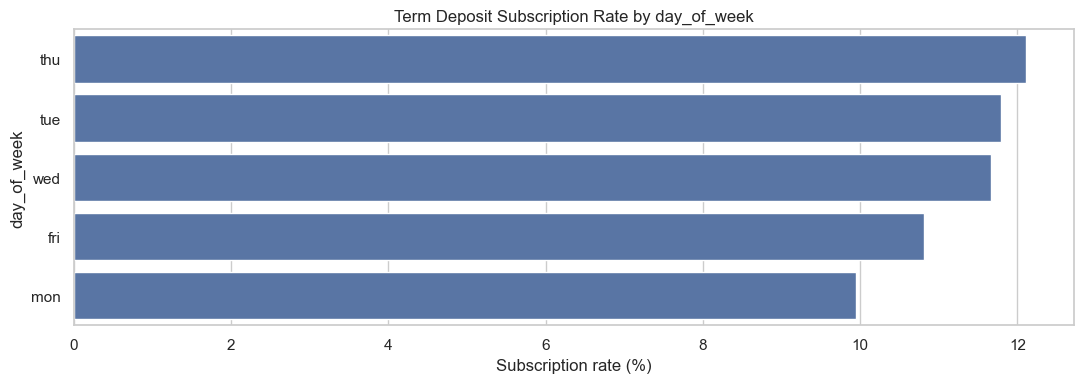

\nSubscription by poutcome


,poutcome,customers,subscriptions,subscription_rate_pct
2,success,1373,894,65.112891
0,failure,4252,605,14.228598
1,nonexistent,35551,3140,8.832382


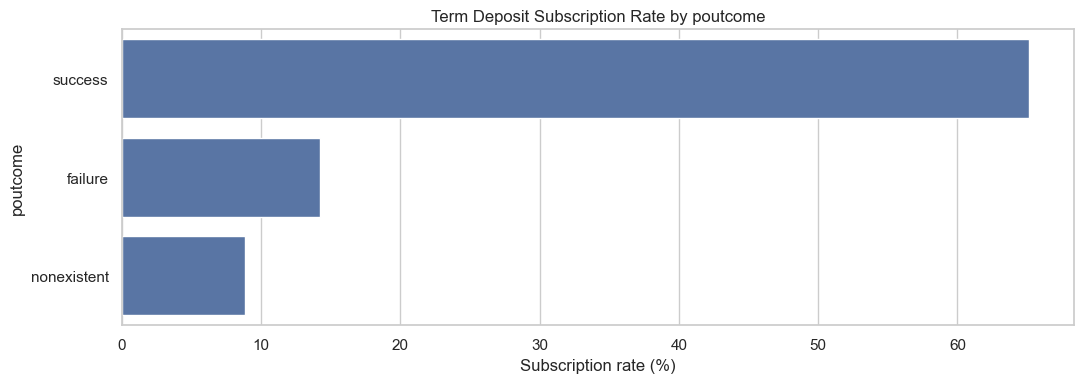

In [10]:
def plot_subscription_rate(data, column, min_count=30, top_n=None):
    summary = (data.groupby(column, dropna=False)
               .agg(customers=("y", "size"),
                    subscriptions=("y", lambda s: (s == "yes").sum()))
               .reset_index())
    summary["subscription_rate_pct"] = summary["subscriptions"] / summary["customers"] * 100
    summary = summary[summary["customers"] >= min_count]
    summary = summary.sort_values("subscription_rate_pct", ascending=False)
    if top_n:
        summary = summary.head(top_n)
    display(summary)

    plt.figure(figsize=(11, max(4, len(summary) * 0.35)))
    sns.barplot(data=summary, x="subscription_rate_pct", y=column)
    plt.title(f"Term Deposit Subscription Rate by {column}")
    plt.xlabel("Subscription rate (%)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()
    return summary

profile_cols = ["job", "marital", "education", "default", "housing", "loan",
                "contact", "month", "day_of_week", "poutcome"]
profile_results = {}
for col in profile_cols:
    if col in df_analysis.columns:
        print(f"\\nSubscription by {col}")
        profile_results[col] = plot_subscription_rate(df_analysis, col)


## 11. Age group analysis

,age_group,customers,subscriptions,subscription_rate_pct
0,18–24,1067,256,23.992502
1,25–34,13684,1666,12.174803
2,35–44,13495,1168,8.655057
3,45–54,8702,752,8.641692
4,55–64,3566,484,13.572630
5,65+,662,313,47.280967


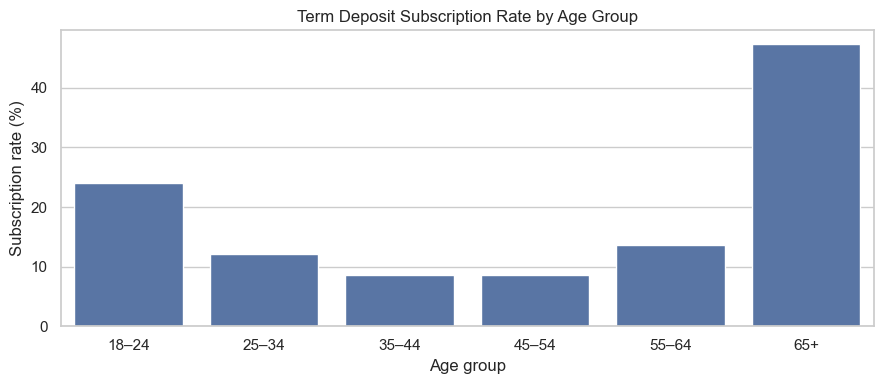

In [11]:
age_bins = [0, 25, 35, 45, 55, 65, 100]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
df_analysis["age_group"] = pd.cut(df_analysis["age"], bins=age_bins,
                                  labels=age_labels, right=False)

age_summary = (df_analysis.groupby("age_group", observed=False)
               .agg(customers=("y", "size"),
                    subscriptions=("y", lambda s: (s == "yes").sum()))
               .reset_index())
age_summary["subscription_rate_pct"] = (
    age_summary["subscriptions"] / age_summary["customers"] * 100
)
display(age_summary)

plt.figure(figsize=(9, 4))
sns.barplot(data=age_summary, x="age_group", y="subscription_rate_pct")
plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Subscription rate (%)")
plt.tight_layout()
plt.show()


## 12. Campaign contact analysis

,campaign,customers,subscriptions,subscription_rate_pct
0,1,17634,2299,13.037314
1,2,10568,1211,11.459122
2,3,5340,574,10.749064
3,4,2650,249,9.396226
4,5,1599,120,7.504690
5,6,979,75,7.660878
6,7,629,38,6.041335
7,8,400,17,4.250000
8,9,283,17,6.007067
9,10,225,12,5.333333


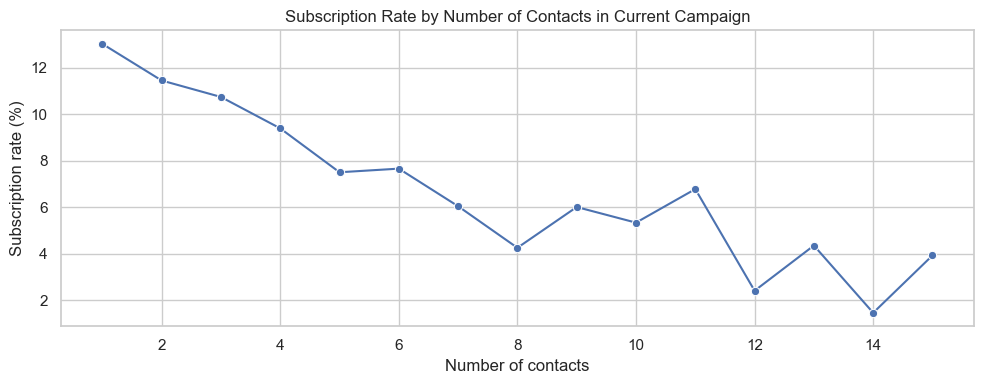

y,no,yes
previously_contacted,,
No,90.74,9.26
Yes,36.17,63.83


In [12]:
# Number of contacts during current campaign
campaign_summary = (df_analysis.groupby("campaign")
                    .agg(customers=("y", "size"),
                         subscriptions=("y", lambda s: (s == "yes").sum()))
                    .reset_index())
campaign_summary["subscription_rate_pct"] = (
    campaign_summary["subscriptions"] / campaign_summary["customers"] * 100
)
display(campaign_summary.head(20))

plt.figure(figsize=(10, 4))
sns.lineplot(data=campaign_summary[campaign_summary["campaign"] <= 15],
             x="campaign", y="subscription_rate_pct", marker="o")
plt.title("Subscription Rate by Number of Contacts in Current Campaign")
plt.xlabel("Number of contacts")
plt.ylabel("Subscription rate (%)")
plt.tight_layout()
plt.show()

# pdays: special value 999 means no prior contact
df_analysis["previously_contacted"] = np.where(df_analysis["pdays"] == 999, "No", "Yes")
display(pd.crosstab(df_analysis["previously_contacted"], df_analysis["y"],
                    normalize="index").mul(100).round(2))


## 13. Numerical correlation analysis

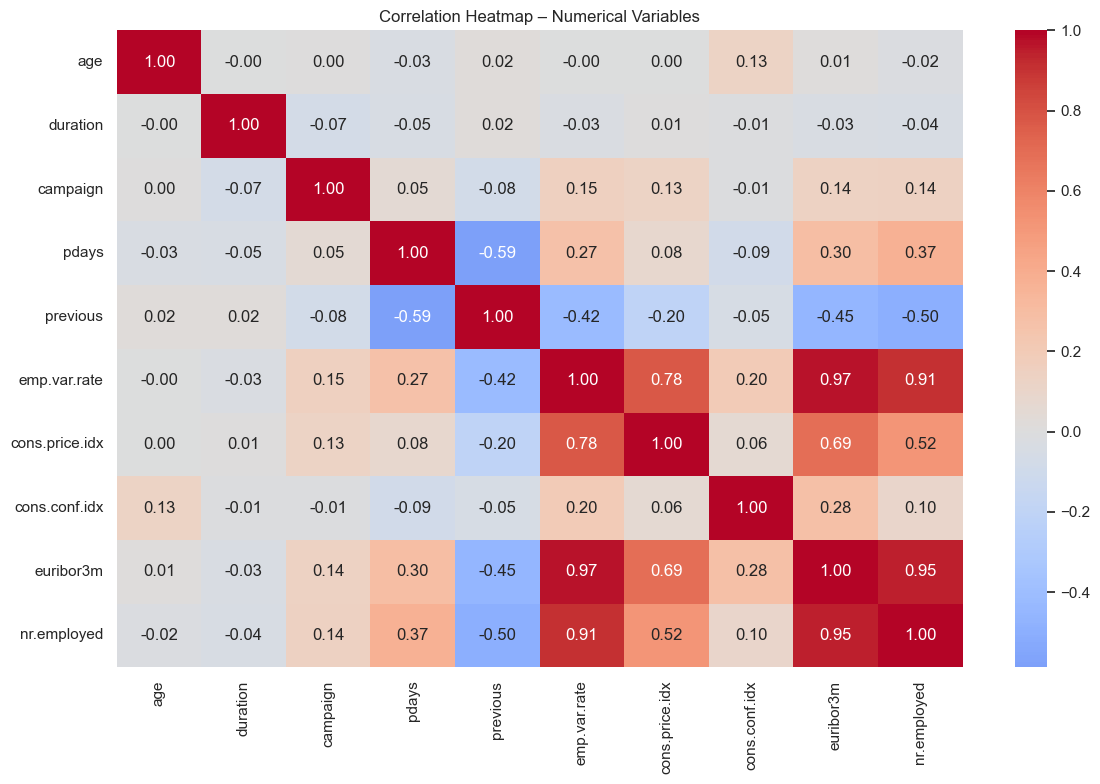

In [13]:
corr = df_analysis[num_cols].corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap – Numerical Variables")
plt.tight_layout()
plt.show()

# Correlation with duration is descriptive only; duration is not available before a call.


## 14. Key findings generated from this dataset

In [14]:
# Data-backed headline findings
target_counts_clean = df_analysis["y"].value_counts()
yes_n = int(target_counts_clean.get("yes", 0))
no_n = int(target_counts_clean.get("no", 0))
total_n = len(df_analysis)
print(f"1. Analysed records after duplicate removal: {total_n:,}.")
print(f"2. Subscribed: {yes_n:,} ({yes_n/total_n*100:.2f}%).")
print(f"3. Did not subscribe: {no_n:,} ({no_n/total_n*100:.2f}%).")

for col in ["job", "education", "contact", "month", "poutcome"]:
    if col in df_analysis.columns:
        s = (df_analysis.groupby(col)["y"]
             .apply(lambda x: (x == "yes").mean() * 100)
             .sort_values(ascending=False))
        print(f"\\nHighest observed subscription rate by {col}:")
        print(s.head(3).round(2).to_string())

print("\\nReminder: group rates should be interpreted together with group sizes.")


1. Analysed records after duplicate removal: 41,176.
2. Subscribed: 4,639 (11.27%).
3. Did not subscribe: 36,537 (88.73%).
\nHighest observed subscription rate by job:
job
student       31.43
retired       25.26
unemployed    14.20
\nHighest observed subscription rate by education:
education
illiterate           22.22
unknown              14.51
university.degree    13.72
\nHighest observed subscription rate by contact:
contact
cellular     14.74
telephone     5.23
\nHighest observed subscription rate by month:
month
mar    50.55
dec    48.90
sep    44.91
\nHighest observed subscription rate by poutcome:
poutcome
success        65.11
failure        14.23
nonexistent     8.83
\nReminder: group rates should be interpreted together with group sizes.


## 15. Business insights and recommendations

Use the tables and charts above to validate these points before presenting them:

1. **Target imbalance:** The `yes` group is much smaller than the `no` group. In later predictive modelling, do not judge a model by accuracy alone; include precision, recall, F1-score and the confusion matrix.
2. **Customer segmentation:** Compare subscription rates by job, age group, education and marital status. Prioritize segments only when both their conversion rate and customer count are meaningful.
3. **Campaign timing:** Use the month and weekday charts to identify periods with stronger observed response. Plan campaign capacity around validated patterns.
4. **Previous campaign outcome:** Compare `poutcome` groups. Customers with a previous successful outcome may be a useful segment for follow-up, subject to business validation.
5. **Contact frequency:** Review conversion rate against `campaign`. Avoid assuming that more calls always produce more subscriptions; repeated contacts may have diminishing returns.
6. **Contact channel:** Compare cellular and telephone response rates and evaluate cost per successful subscription before reallocating budget.
7. **Responsible targeting:** Use customer information fairly, follow applicable privacy/marketing-consent rules, and provide customers with an easy way to decline further calls.

**Important modelling caution:** `duration` is strongly associated with the final call outcome but is known only after the call. It may be shown in this descriptive report, but it must be excluded from a model intended to select customers before calling.

## 16. Challenges faced and techniques used

In [15]:
challenges = pd.DataFrame([
    ["Class imbalance", "The number of 'no' responses is much larger than 'yes'.",
     "Report class-wise metrics; in Task 2 consider class weights or resampling using training data only."],
    ["Unknown categories", "Several categorical columns can contain the literal value 'unknown'.",
     "Quantify unknown values and decide whether to retain them as a separate category."],
    ["Special pdays code", "999 means the customer was not previously contacted.",
     "Create a previously_contacted indicator; do not interpret 999 as an ordinary day count."],
    ["Data leakage risk", "duration is known only after the call.",
     "Exclude duration from a pre-call production prediction model."],
    ["Repeated records", "Exact duplicate rows may occur.",
     "Count duplicates and analyse a deduplicated copy; document the choice."],
    ["Different variable types", "The dataset mixes numerical and categorical features.",
     "Use separate summaries/plots and appropriate encoding in the modelling task."]
], columns=["Challenge", "Why it matters", "Technique / reason"])
display(challenges)


,Challenge,Why it matters,Technique / reason
0,Class imbalance,The number of 'no' responses is much larger th...,Report class-wise metrics; in Task 2 consider ...
1,Unknown categories,Several categorical columns can contain the li...,Quantify unknown values and decide whether to ...
2,Special pdays code,999 means the customer was not previously cont...,Create a previously_contacted indicator; do no...
3,Data leakage risk,duration is known only after the call.,Exclude duration from a pre-call production pr...
4,Repeated records,Exact duplicate rows may occur.,Count duplicates and analyse a deduplicated co...
5,Different variable types,The dataset mixes numerical and categorical fe...,Use separate summaries/plots and appropriate e...


## 17. Final conclusion

This analysis describes customer characteristics, campaign activity and economic indicators associated with term-deposit subscription. The target variable is `y`. The observed subscription rate is relatively low compared with non-subscription, so the bank should focus on evidence-based customer segmentation and evaluate marketing performance by conversion rate and customer count.


# TASK 2: PREDICTIVE MODEL

 **Objective**
To build a machine learning model that predicts whether a customer will subscribe to a term deposit.

##  1: Import Required Libraries

Import the required libraries for data preprocessing, model building and performance evaluation.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve

## 2: Create Model Dataset

Create a separate copy of the cleaned dataset for predictive modelling.

In [17]:
df_model = df_analysis.copy()

df_model.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,age_group,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,55–64,No
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,55–64,No
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,35–44,No
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,35–44,No
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,55–64,No


### 3. Data Cleaning and Preprocessing

In This step, we check the dataset for missing values, duplicate records, and unknown
values. We clean the data to prepare it for machine learning models.

In [18]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check unknown values
print("\nUnknown Values:")
print((df == "unknown").sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

### 4. Removing Duplicate Records

In this step, duplicate records are removed from the dataset to avoid
repeated information and improve data quality.

In [19]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

print("Updated Dataset Shape:", df.shape)

Duplicates before cleaning: 12
Duplicates after cleaning: 0
Updated Dataset Shape: (41176, 21)


### 5. Separating Features and Target Variable

In this step, we separate the independent variables (features) and dependent variable (target).
    The target variable is 'y', which indicates whether a customer subscribed to a term deposit.

In [20]:
X = df.drop(columns=["y", "duration"])

y = df["y"].map({"no": 0, "yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (41176, 19)
Target Shape: (41176,)

Target Distribution:
y
0    36537
1     4639
Name: count, dtype: int64


### 6. Splitting Data into Training and Testing Sets

In this step, the dataset is divided into training and testing sets. 
    The training set is used to train the machine learning models,
while the testing set is used to evaluate their performance.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (32940, 19)
Testing Data Shape: (8236, 19)
Training Target Shape: (32940,)
Testing Target Shape: (8236,)


### 7. Data Preprocessing

In [22]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("Libraries imported successfully!")

Libraries imported successfully!


In [23]:
#Identify Numerical and Categorical Columns
numeric_features = X_train.select_dtypes(include=np.number).columns

categorical_features = X_train.select_dtypes(exclude=np.number).columns

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 9
Categorical Features: 10


In [24]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


### 8. Building Machine Learning Models
Build four classification models: Logistic Regression, Decision Tree, Random Forest and K-Nearest Neighbors (KNN).

1.Logistic Regression

2.Decision Tree

3.Random Forest

4.K-Nearest Neighbors (KNN)

In [25]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("All 4 Models Created Successfully!")

All 4 Models Created Successfully!


## 9. Training and Evaluating Models

Train all four machine learning algorithms using the training dataset.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Evaluation Metrics Imported Successfully!")

Evaluation Metrics Imported Successfully!


In [27]:
results = []
trained_models = {}

for name, model in models.items():

    clf = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

    trained_models[name] = clf

print("All 4 Models Trained Successfully!")

All 4 Models Trained Successfully!


### 10. Model Performance Comparison

In [28]:
# Convert results into a DataFrame
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,Random Forest,0.872997,0.452951,0.612069,0.520623,0.806609,0.486473
0,Logistic Regression,0.830257,0.359113,0.645474,0.461479,0.800231,0.446267
1,Decision Tree,0.823458,0.349714,0.659483,0.457058,0.795316,0.444485
3,KNN,0.895580,0.567194,0.309267,0.400279,0.740429,0.350406


### 11. Model Performance Visualization

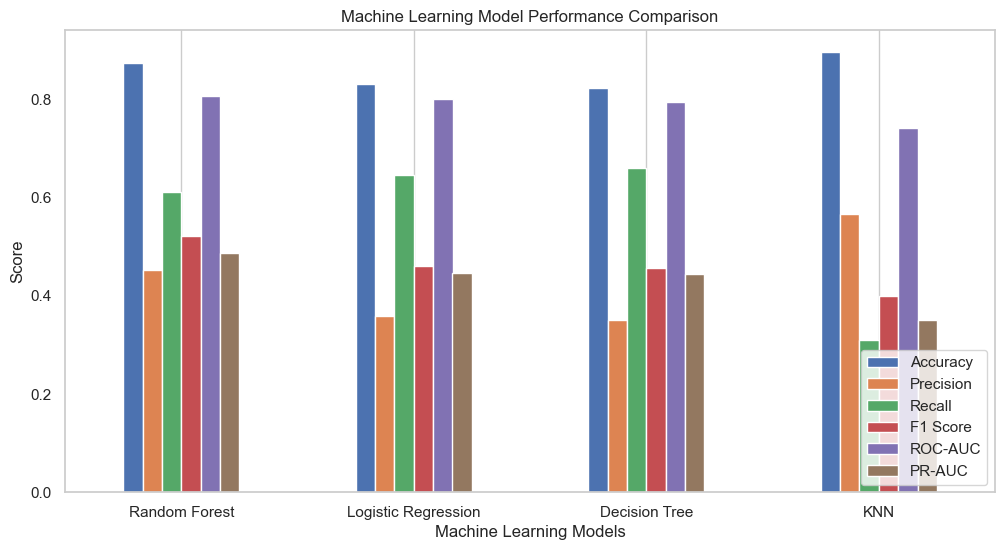

In [29]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

### 12. Confusion Matrix of All 4 Models

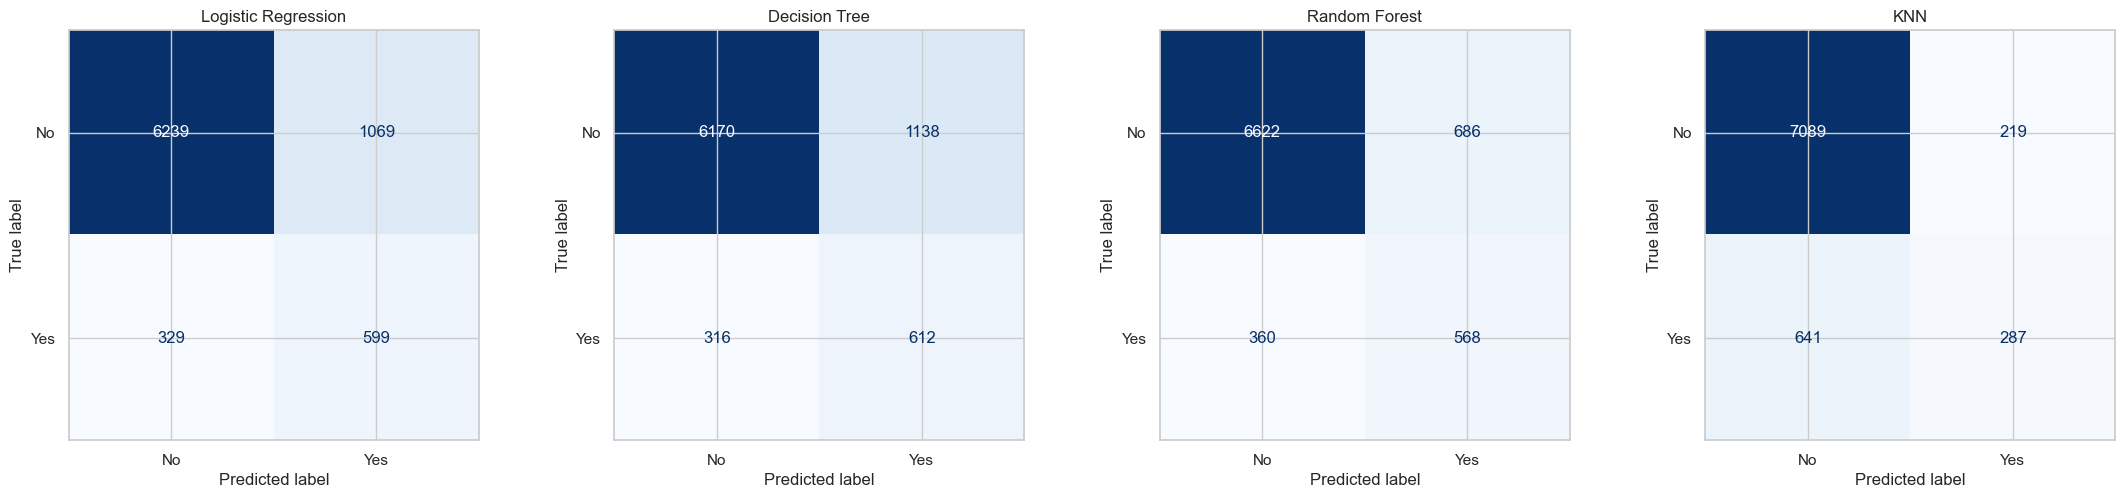

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (name, clf) in zip(axes, trained_models.items()):

    y_pred = clf.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)
plt.tight_layout()
plt.show()

### 13. ROC Curve Comparison

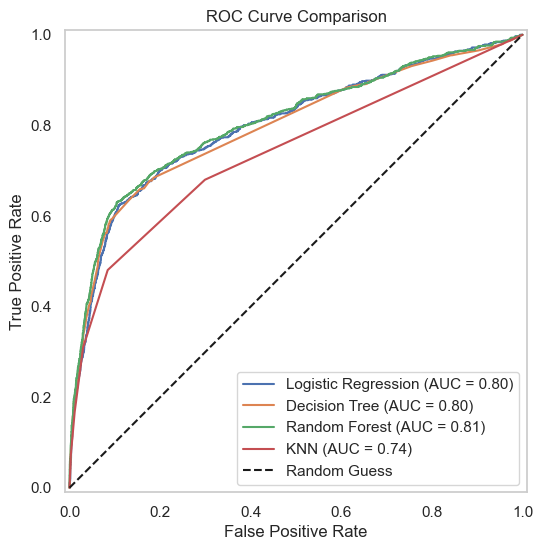

In [31]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 6))

for name, clf in trained_models.items():

    y_prob = clf.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Guess"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

### 14. Best Model Selection

In [32]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("Best PR-AUC Score:", results_df.iloc[0]["PR-AUC"])

Best Model: Random Forest
Best PR-AUC Score: 0.486472966192934


### 15. Classification Report of Best Model

In [33]:
from sklearn.metrics import classification_report

y_pred_best = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["No", "Yes"]
    )
)

Best Model: Random Forest

Classification Report:

              precision    recall  f1-score   support

          No       0.95      0.91      0.93      7308
         Yes       0.45      0.61      0.52       928

    accuracy                           0.87      8236
   macro avg       0.70      0.76      0.72      8236
weighted avg       0.89      0.87      0.88      8236



### 16. Challenges Faced During Predictive Modelling

1. Imbalanced Dataset: The number of customers who subscribed was much lower than those who did not.

2. Missing and Unknown Values: Some categorical columns contained unknown values.

3. Data Preprocessing: Numerical and categorical data required different preprocessing techniques.

4. Feature Selection: The duration column was excluded because it is known only after the phone call.

5. Model Selection: Four machine learning algorithms were tested.

6. Model Evaluation: Multiple evaluation metrics were used to compare model performance.

**Conclusion :**

Four Machine Learning models were developed to predict whether a customer will subscribe to the bank's term deposit.
The models used were:

Logistic Regression
Decision Tree
Random Forest
K-Nearest Neighbors (KNN)

The models were evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC and PR-AUC.

The selected best model achieved an accuracy of 87%. For customers who subscribed to the term deposit (Yes class), the model achieved a recall of 61% and an F1-score of 52%.

The model performs better at identifying customers who do not subscribe than customers who subscribe. This is mainly because the dataset contains more No responses than Yes responses.

Overall, the predictive model can help the bank's marketing team identify potential customers. Further improvements can be made to increase the prediction performance for the Yes class.

# Task 3 – Suggestions to the Bank Marketing Team

**Introduction**

The objective of this task is to provide data-driven business recommendations to the bank's marketing team to improve term deposit subscriptions.

These recommendations are based on:
- Task 1: Exploratory Data Analysis and Business Insights.
- Task 2: Predictive Modelling and Model Performance Evaluation.

The analysis helps identify customer subscription patterns, while the predictive model helps identify potential customers.

By combining data analysis and machine learning, the bank can improve customer targeting, optimize marketing campaigns and increase subscription opportunities.

### 1. Key Insights from Task 1 – Data Analysis

1. The dataset contains 41,176 analysed customer records.
2. Only 11.27% of customers subscribed to term deposits, while 88.73% did not subscribe.
3. Students showed an observed subscription rate of 31.43%, followed by retired customers at 25.26%.
4. Cellular contact showed a subscription rate of 14.74%, compared with 5.23% for telephone contact.
5. March, December and September showed higher observed subscription rates among the months.
6. Customers with a previous successful campaign outcome showed a 65.11% subscription rate.

**Business Interpretation:**

These findings indicate that customer segmentation, previous campaign outcomes and communication channels can help the bank plan more effective marketing campaigns.

Note: Subscription rates should be considered along with customer counts before making targeting decisions.

### 2. Key Insights from Task 2 – Predictive Modelling

1. Four machine learning models were developed:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - K-Nearest Neighbors (KNN)

2. Random Forest achieved the highest PR-AUC score of approximately 0.4865 and was selected as the best model.

3. The selected model achieved:
   - Accuracy: 87%
   - Yes Precision: 45%
   - Yes Recall: 61%
   - Yes F1-Score: 52%

4. The model identifies approximately 61% of actual subscribers.

**Business Interpretation:**

The Random Forest model can help the bank identify potential subscribers. However, further improvement in precision and recall is required to reduce incorrect predictions and identify more interested customers.

# 3. Suggestions to the Bank Marketing Team

**1. Target Potential Customers**
- Use the Random Forest model to identify customers with higher subscription probabilities.
- Prioritize potential customers for marketing campaigns.
- Verify customer interest before repeated follow-up calls.

**2. Focus on Customer Segmentation**
- Study customer groups such as students, retired customers and other job categories.
- Compare subscription rates and customer counts before selecting target segments.
- Create suitable marketing strategies for different customer groups.

**3. Improve Communication Channels**
- Analyse the observed difference between cellular and telephone subscription rates.
- Evaluate campaign costs and conversion rates before allocating more resources to a channel.

**4. Use Previous Campaign Results**
- Give attention to customers with previous successful campaign outcomes.
- Study unsuccessful campaign reasons.
- Avoid repeating ineffective marketing approaches.

**5. Optimize Campaign Timing**
- Review monthly and weekday subscription patterns.
- Plan campaign schedules using validated customer response trends.

**6. Reduce Unnecessary Calls**
- Avoid contacting customers too frequently.
- Use customer interest and previous responses to plan follow-ups.
- Focus on meaningful customer interactions.

**7. Improve Model Performance**
- Monitor Precision, Recall, F1-score and PR-AUC.
- Experiment with class weighting and threshold tuning.
- Evaluate model performance regularly using new customer data.

**8. Conduct A/B Testing**
- Test different marketing messages and communication strategies.
- Compare subscription conversion rates.
- Adopt strategies that show better results.

# 4. Key Performance Indicators (KPIs)

The bank should monitor the following KPIs to measure marketing campaign effectiveness:

**1. Subscription Conversion Rate:** Percentage of contacted customers who subscribe to term deposits.

**2. Campaign Success Rate:** Number of successful subscriptions compared with total campaign contacts.

**3. Customer Acquisition Cost:** Marketing cost incurred for each successful subscription.

**4. Model Recall:** Percentage of actual subscribers correctly identified by the predictive model.

**5. Model Precision:** Percentage of customers predicted as subscribers who actually subscribe.

**6. Customer Response Rate:** Percentage of customers who respond positively to marketing campaigns.

**7. Campaign Contact Frequency:** Average number of calls made to each customer.

The bank should establish baseline values and set improvement targets based on campaign performance.

# 5. Final Conclusion

The Portuguese Bank Marketing project demonstrates how data analysis and machine learning can support effective marketing decisions.

**Task 1:** identified important customer subscription patterns, including differences across customer segments, communication channels and previous campaign outcomes.

**Task 2:** developed four predictive models, with Random Forest selected based on its PR-AUC performance. The selected model achieved 87% accuracy and 61% recall for the Yes class.

Based on these findings, the bank should focus on potential customer identification, customer segmentation, effective communication channels and optimized campaign strategies.

Regular monitoring of business KPIs and predictive model performance can help improve marketing efficiency.

Overall, combining data analytics, predictive modelling and data-driven recommendations can help the bank improve customer engagement and increase term deposit subscriptions.

# 6. Model Comparison Report

Four Machine Learning algorithms were implemented and evaluated for predicting customer subscription to the bank's term deposit.

The models used were:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)

### Evaluation Metrics

The models were compared using the following metrics:

- Accuracy: Measures overall prediction correctness.
- Precision: Measures how many predicted Yes customers actually subscribed.
- Recall: Measures how many actual Yes customers were correctly identified.
- F1-Score: Balances Precision and Recall.
- ROC-AUC: Measures the model's ability to distinguish between classes.
- PR-AUC: Evaluates model performance, especially for the minority class.

| Model | Accuracy | F1 Score | PR-AUC |
|---|---|---|---|
| Random Forest | 0.8730 | 0.5206 | 0.4865 |
| Logistic Regression | 0.8303 | 0.4615 | 0.4463 |
| Decision Tree | 0.8235 | 0.4571 | 0.4445 |
| KNN | 0.8956 | 0.4003 | 0.3504 |

### Comparison Result

The model comparison shows that different algorithms have different prediction performances.

Since the dataset is imbalanced, PR-AUC, Recall and F1-Score are important metrics for selecting the best model.

The best-performing model was selected based on PR-AUC score.

### Conclusion

The comparison of four machine learning models helps identify a suitable model for predicting potential term deposit customers.

The selected model can support the bank's marketing team in improving customer targeting and campaign effectiveness.

# 7. Overall Report on Challenges Faced

During the Portuguese Bank Marketing project, several challenges were encountered during data analysis, preprocessing and model building.

### 1. Data Understanding
Understanding the dataset, its features and the business objective was an initial challenge.

### 2. Missing and Unknown Values
Some categorical columns contained unknown values, which required careful handling.

### 3. Class Imbalance
The dataset contained significantly more No responses than Yes responses, making customer subscription prediction challenging.

### 4. Data Preprocessing
Numerical and categorical features required different preprocessing techniques such as scaling and encoding.

### 5. Feature Selection
The duration feature was excluded from predictive modelling because it is known only after the marketing call.

### 6. Model Performance
Improving the prediction of customers who actually subscribe was challenging.

### 7. Model Evaluation
Different evaluation metrics such as Accuracy, Precision, Recall, F1-Score, ROC-AUC and PR-AUC were required to compare models.

### Conclusion

The project provided practical experience in data cleaning, exploratory data analysis, feature engineering and machine learning.

These challenges helped in understanding real-world data science problems and the importance of selecting appropriate techniques for building predictive models.